In [1]:
import torch 
import sys 
import pandas as pd 
import numpy as np 
import networkx as nx 

print(f'torch=={torch.__version__}') 
print(f'pandas=={pd.__version__}') 
print(f'numpy=={np.__version__}') 
print(f'networkx=={nx.__version__}') 

import tqdm 
import matplotlib.pyplot as plt 
from itertools import chain 

sys.path.append('.') 
from agfn.gflownet import GFlowNet 
from agfn.gym import MAG, LogReward 
from agfn.models import KGForwardPolicy, BackwardPolicy  
from agfn.utils import train 

torch==2.2.1+cu121
pandas==2.2.2
numpy==1.26.3
networkx==3.3


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 
print(f'Device: {device}') 

Device: cuda


This tutorial shows how to train an AGFN using a custom dataset. In the near future, it will be expanded and improved. 

## Load the data

In [3]:
torch.set_default_dtype(torch.float64) 

In [4]:
data = pd.read_csv('data/chain4_dat01.csv') 
node_labels = data.columns.tolist() 
data = torch.tensor(data.values, device=device, dtype=torch.get_default_dtype()) 
num_nodes = data.shape[1] 
print(f'Number of variables: {num_nodes}') 

Number of variables: 4


## Instantiate the model 

In [5]:
pf = KGForwardPolicy(num_nodes, num_layers=2, hidden_dim=256, device=device) 
pb = BackwardPolicy(device) 
gflownet = GFlowNet(pf, pb, criterion='tb', device=device) 

In [6]:
create_env = lambda batch_size=64: MAG(num_nodes, batch_size, log_reward, device=device) 

In [7]:
log_reward = LogReward(dataset=data, device=device) 
log_reward.warmup(gflownet, create_env, 32)

## Train the model 

In [8]:
# losses = train(gflownet, create_env, epochs=int(512)) 

In [9]:
# plt.figure(figsize=(2, 2)) 
# plt.plot(losses) 

## Human-in-the-loop pipeline  

We provide a less-principled but more-practical alternative to our HITL pipeline. 

In a nutshell, each action at a state $s$ corresponds to the addition of an edge $e$ between nodes $i$ and $j$. 

Complementarily, an expert provides a probability distribution over this specific edge. Under these conditions, a sensible and efficient strategy for sampling would consists of weighting each _action_ according to the expert's feedback. 

Specifically, the expert's feedback is still assumed to be sampled from a categorical distribution $\text{Cat}(\alpha_{ij})$ for each edge $\{i, j\}$ and $\alpha_{ij} \in \mathbb{R}^{4}$. We fix a Dirichlet prior $\pi$ over $\alpha_{ij}$. Heuristically, $\pi$ defines the level of the expert's reliability. For inference, we use the MAP estimate of $\alpha_{ij}$ when sampling actions. In more detail, let $C = (c_{1}, \dots, c_{4})$ be the feedbacks (counts) for a edge $\{i, j\}$; the posterior distribution is 

$$ 
    \pi(\alpha_{ij} | C) = \frac{\pi(\alpha_{ij}) \cdot f(C | \alpha_{ij})}{\int \pi(\alpha_{ij}) f(C | \alpha_{ij}) \mathrm{d}\alpha_{ij}}, 
$$ 

which is a Dirichlet distribution. The MAP estimate for $\alpha_{ij}$ is then 

$$ 
    \hat{\alpha}_{ij} = \frac{
        C + \beta - 1   
    }{\left(\sum_{1 \le m \le 4} C_{m} + \beta_{m}\right) - 4}. % , 
$$ 

This $\hat{\alpha}_{ij}$ is used to weight the GFlowNet's actions.   

When the expert provides a probability distribution as a feedback, we use their feedback as an estimate for $\alpha_{ij}$. 

Additionally, when the expert provides a confidence score for a specific relationship, e.g., of ancestrality, we distributed the remaining probability mass uniformly among the alternatives. 

Importantly, these settings accommodate the three common scenarios below: 

1. when feedback is gathered from pooling, e.g., from the internet or Amazon Mechanical Turk, 
2. when the feedback is provided by a statistical model based on external evidence, 
3. when the feedback corresponds to a subjective probability estimate. 

We focus the implementation below on the scenario (2). A similar strategy may be employed for (1) and (3) also. 

Define a prior, uniform feedback. 

In [10]:
max_num_edges = ((data.shape[1]) * (data.shape[1] - 1)) // 2 
feedbacks = torch.ones((max_num_edges, 4), device=device) 
feedbacks = feedbacks / feedbacks.sum(dim=1, keepdims=True)

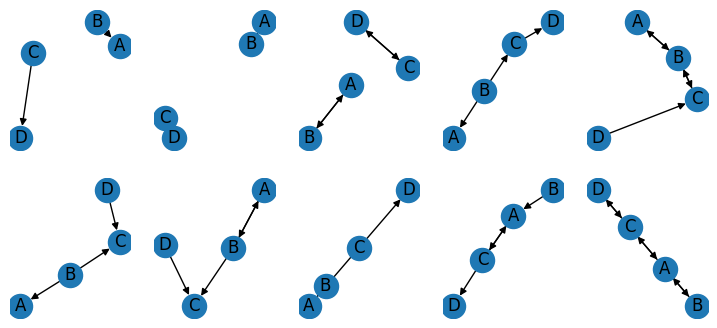

In [11]:
gflownet.eval() 
env = gflownet.sample(create_env(512)) 
plt.figure(figsize=(9, 4)) 
indices = torch.topk(env.log_reward(), k=10).indices 
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    env.draw(i, labels=node_labels) 

## Knowledge elicitation framework 

The development of a knowledge elicitation framework depends critically on the nature of the feedback provided by the expert. 

Ideally, we would have a probability distribution $p$ over the feedbacks (e.g., a categorical for the pooling-based approach or a Dirichlet for the subjective probabilities) and choose to query the expert about the edge that maximizes an expected functional over this metric. 

This can be developed, and should be relatively straightforward to implement for most cases. However, we stick below with a determistic ordering for the queries.  

In [38]:
from agfn.hitl import sample_massive_batch 

In [39]:
querying_order = torch.arange(
    max_num_edges - 2 
)

In [40]:
def get_oracle_feedback(query):  
    true_graph = torch.tensor([
        [0, 1, 0, 0], # (A, B)
        [1, 0, 0, 0], # (A, C)
        [1, 0, 0, 0], # (A, D)
        [0, 1, 0, 0], # (B, C)
        [1, 0, 0, 0], # (B, D)
        [0, 1, 0, 0], # (C, D) 
    ], device=device) 
    return true_graph[query] # The expert is an oracle 

In [41]:
feedbacks_oracle = feedbacks.clone() 

In [42]:
for query in querying_order: 
    feedbacks_oracle[query] = get_oracle_feedback(query) 

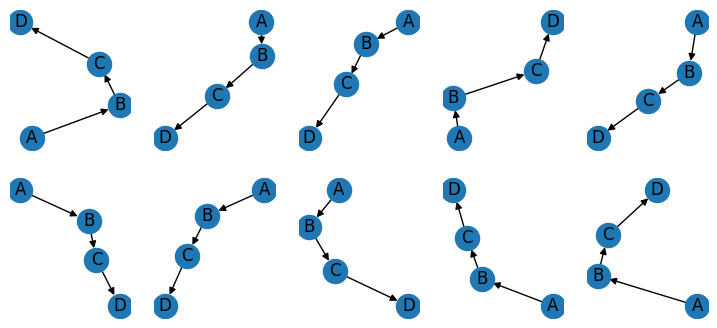

In [46]:
gflownet.eval() 
plt.figure(figsize=(9, 4)) 
samples = gflownet.sample(create_env(512), feedbacks=feedbacks_oracle)  
indices = torch.topk(samples.log_reward(), k=10).indices 
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    samples.draw(i, labels=node_labels) 

In [34]:
def get_unreliable_expert_feedback(query, pi=.95):  
    # `pi` is our level of confidence on the expert 
    true_graph = torch.tensor([
        [0, 1, 0, 0], # (A, B)
        [1, 0, 0, 0], # (A, C)
        [1, 0, 0, 0], # (A, D)
        [0, 1, 0, 0], # (B, C)
        [1, 0, 0, 0], # (B, D)
        [0, 1, 0, 0], # (C, D) 
    ], device=device)
    true_graph = pi * true_graph + (1 - true_graph) * (1 - pi) / 3  
    return true_graph[query] # The expert is an oracle 

In [35]:
feedbacks_unreliable = feedbacks.clone() 

In [36]:
for query in querying_order: 
    feedbacks_unreliable[query] = get_unreliable_expert_feedback(query) 

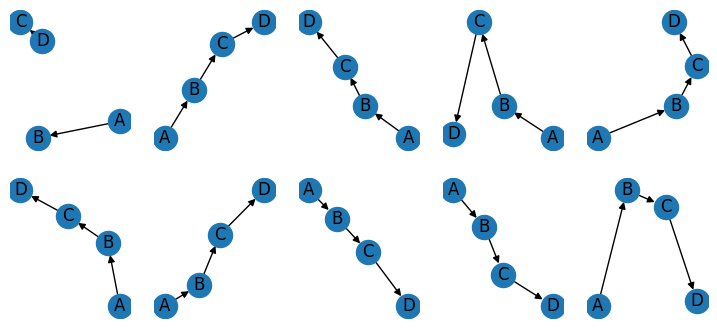

In [45]:
gflownet.eval() 
plt.figure(figsize=(9, 4)) 
samples = gflownet.sample(create_env(512), feedbacks=feedbacks_unreliable)  
indices = torch.topk(samples.log_reward(), k=10).indices 
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    samples.draw(i, labels=node_labels) 